In [4]:
import pandas as pd
df = pd.read_csv('openpowerlifting.csv')
df.head()

,MeetID,Name,Sex,Equipment,Age,Division,BodyweightKg,WeightClassKg,Squat4Kg,BestSquatKg,Bench4Kg,BestBenchKg,Deadlift4Kg,BestDeadliftKg,TotalKg,Place,Wilks
0,0,Angie Belk Terry,F,Wraps,47.0,Mst 45-49,59.60,60,NaN,47.63,NaN,20.41,NaN,70.31,138.35,1,155.05
1,0,Dawn Bogart,F,Single-ply,42.0,Mst 40-44,58.51,60,NaN,142.88,NaN,95.25,NaN,163.29,401.42,1,456.38
2,0,Dawn Bogart,F,Single-ply,42.0,Open Senior,58.51,60,NaN,142.88,NaN,95.25,NaN,163.29,401.42,1,456.38
3,0,Dawn Bogart,F,Raw,42.0,Open Senior,58.51,60,NaN,NaN,NaN,95.25,NaN,NaN,95.25,1,108.29
4,0,Destiny Dula,F,Raw,18.0,Teen 18-19,63.68,67.5,NaN,NaN,NaN,31.75,NaN,90.72,122.47,1,130.47


In [5]:
df = df.drop_duplicates(subset=['Name'])
df.head()

,MeetID,Name,Sex,Equipment,Age,Division,BodyweightKg,WeightClassKg,Squat4Kg,BestSquatKg,Bench4Kg,BestBenchKg,Deadlift4Kg,BestDeadliftKg,TotalKg,Place,Wilks
0,0,Angie Belk Terry,F,Wraps,47.0,Mst 45-49,59.60,60,NaN,47.63,NaN,20.41,NaN,70.31,138.35,1,155.05
1,0,Dawn Bogart,F,Single-ply,42.0,Mst 40-44,58.51,60,NaN,142.88,NaN,95.25,NaN,163.29,401.42,1,456.38
4,0,Destiny Dula,F,Raw,18.0,Teen 18-19,63.68,67.5,NaN,NaN,NaN,31.75,NaN,90.72,122.47,1,130.47
5,0,Courtney Norris,F,Wraps,28.0,Open Senior,62.41,67.5,-183.7,170.10,NaN,77.11,NaN,145.15,392.36,1,424.40
6,0,Maureen Clary,F,Raw,60.0,Mst 60-64,67.31,67.5,NaN,124.74,NaN,95.25,NaN,163.29,383.28,1,391.98


In [6]:
df.shape

(136687, 17)

In [9]:
df.isna().sum()

,0
MeetID,0
Name,0
Sex,0
Equipment,0
Age,82737
Division,6412
BodyweightKg,942
WeightClassKg,1447
Squat4Kg,136217
BestSquatKg,27294


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 136687 entries, 0 to 386412
Data columns (total 17 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   MeetID          136687 non-null  int64  
 1   Name            136687 non-null  object 
 2   Sex             136687 non-null  object 
 3   Equipment       136687 non-null  object 
 4   Age             53950 non-null   float64
 5   Division        130275 non-null  object 
 6   BodyweightKg    135745 non-null  float64
 7   WeightClassKg   135240 non-null  object 
 8   Squat4Kg        470 non-null     float64
 9   BestSquatKg     109393 non-null  float64
 10  Bench4Kg        720 non-null     float64
 11  BestBenchKg     127004 non-null  float64
 12  Deadlift4Kg     1075 non-null    float64
 13  BestDeadliftKg  115994 non-null  float64
 14  TotalKg         128569 non-null  float64
 15  Place           136153 non-null  object 
 16  Wilks           128119 non-null  float64
dtypes: float64(10),

In [11]:
for col in df.columns:
    print(f'{col}: {df[col].isna().sum() / df.shape[0] * 100:.2f}%')

MeetID: 0.00%
Name: 0.00%
Sex: 0.00%
Equipment: 0.00%
Age: 60.53%
Division: 4.69%
BodyweightKg: 0.69%
WeightClassKg: 1.06%
Squat4Kg: 99.66%
BestSquatKg: 19.97%
Bench4Kg: 99.47%
BestBenchKg: 7.08%
Deadlift4Kg: 99.21%
BestDeadliftKg: 15.14%
TotalKg: 5.94%
Place: 0.39%
Wilks: 6.27%


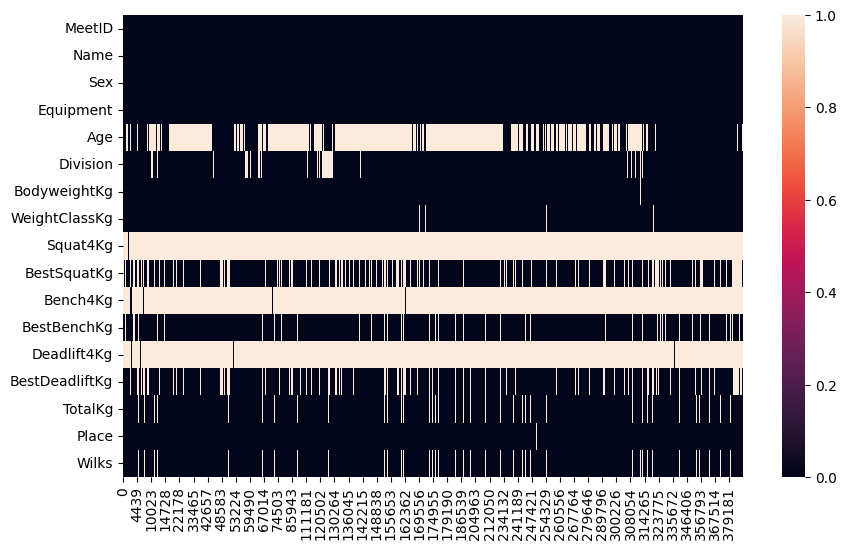

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
sns.heatmap(df.isna().transpose());

Удалить столбцы/строки с пропусками

In [13]:
cols_to_drop = []

for col in df.columns:
    if df[col].isna().sum() / df.shape[0] > 0.7:
        cols_to_drop.append(col)

cols_to_drop

['Squat4Kg', 'Bench4Kg', 'Deadlift4Kg']

In [14]:
df.drop(columns=cols_to_drop)

,MeetID,Name,Sex,Equipment,Age,Division,BodyweightKg,WeightClassKg,BestSquatKg,BestBenchKg,BestDeadliftKg,TotalKg,Place,Wilks
0,0,Angie Belk Terry,F,Wraps,47.0,Mst 45-49,59.60,60,47.63,20.41,70.31,138.35,1,155.05
1,0,Dawn Bogart,F,Single-ply,42.0,Mst 40-44,58.51,60,142.88,95.25,163.29,401.42,1,456.38
4,0,Destiny Dula,F,Raw,18.0,Teen 18-19,63.68,67.5,NaN,31.75,90.72,122.47,1,130.47
5,0,Courtney Norris,F,Wraps,28.0,Open Senior,62.41,67.5,170.10,77.11,145.15,392.36,1,424.40
6,0,Maureen Clary,F,Raw,60.0,Mst 60-64,67.31,67.5,124.74,95.25,163.29,383.28,1,391.98
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
386398,8481,Molly Headly,F,Multi-ply,NaN,Elite,86.73,90,NaN,NaN,220.00,220.00,1,193.20
386402,8481,Bryan Doderdruk,M,Multi-ply,NaN,Elite,97.43,100,NaN,NaN,352.50,352.50,2,216.85
386403,8481,Shawn Schumaker,M,Multi-ply,NaN,Elite,98.79,100,NaN,NaN,365.00,365.00,1,223.24
386406,8481,Matthew Ladewski,M,Multi-ply,NaN,Elite,99.97,100,NaN,NaN,325.00,325.00,4,197.82


.dropna()

In [15]:
tmp = df.dropna()
tmp.shape

(31, 17)

In [16]:
tmp.isna().sum()

,0
MeetID,0
Name,0
Sex,0
Equipment,0
Age,0
Division,0
BodyweightKg,0
WeightClassKg,0
Squat4Kg,0
BestSquatKg,0


axis

In [17]:
tmp = df.dropna(axis=1)  # defaul axis=0
tmp.shape

(136687, 4)

In [18]:
tmp.isna().sum()

,0
MeetID,0
Name,0
Sex,0
Equipment,0


how

In [19]:
tmp = df.dropna(how='all', axis=0)  # defaul how='any'
tmp.shape

(136687, 17)

In [20]:
tmp = df.dropna(how='all', axis=1)  # defaul how='any'
tmp.shape

(136687, 17)

In [21]:
df.loc[len(df)] = [None] * len(df.columns)
df

/tmp/ipython-input-3447395906.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df.loc[len(df)] = [None] * len(df.columns)


,MeetID,Name,Sex,Equipment,Age,Division,BodyweightKg,WeightClassKg,Squat4Kg,BestSquatKg,Bench4Kg,BestBenchKg,Deadlift4Kg,BestDeadliftKg,TotalKg,Place,Wilks
0,0,Angie Belk Terry,F,Wraps,47.0,Mst 45-49,59.60,60,NaN,47.63,NaN,20.41,NaN,70.31,138.35,1,155.05
1,0,Dawn Bogart,F,Single-ply,42.0,Mst 40-44,58.51,60,NaN,142.88,NaN,95.25,NaN,163.29,401.42,1,456.38
4,0,Destiny Dula,F,Raw,18.0,Teen 18-19,63.68,67.5,NaN,NaN,NaN,31.75,NaN,90.72,122.47,1,130.47
5,0,Courtney Norris,F,Wraps,28.0,Open Senior,62.41,67.5,-183.7,170.10,NaN,77.11,NaN,145.15,392.36,1,424.40
6,0,Maureen Clary,F,Raw,60.0,Mst 60-64,67.31,67.5,NaN,124.74,NaN,95.25,NaN,163.29,383.28,1,391.98
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
386402,8481,Bryan Doderdruk,M,Multi-ply,NaN,Elite,97.43,100,NaN,NaN,NaN,NaN,NaN,352.50,352.50,2,216.85
386403,8481,Shawn Schumaker,M,Multi-ply,NaN,Elite,98.79,100,NaN,NaN,NaN,NaN,NaN,365.00,365.00,1,223.24
386406,8481,Matthew Ladewski,M,Multi-ply,NaN,Elite,99.97,100,NaN,NaN,NaN,NaN,NaN,325.00,325.00,4,197.82
386412,8481,Jeff Bumanglag,M,Multi-ply,NaN,Elite,126.73,140,NaN,NaN,NaN,NaN,NaN,320.00,320.00,3,181.85


In [22]:
tmp = df.dropna(how='all', axis=0)  # defaul how='any'
tmp

,MeetID,Name,Sex,Equipment,Age,Division,BodyweightKg,WeightClassKg,Squat4Kg,BestSquatKg,Bench4Kg,BestBenchKg,Deadlift4Kg,BestDeadliftKg,TotalKg,Place,Wilks
0,0,Angie Belk Terry,F,Wraps,47.0,Mst 45-49,59.60,60,NaN,47.63,NaN,20.41,NaN,70.31,138.35,1,155.05
1,0,Dawn Bogart,F,Single-ply,42.0,Mst 40-44,58.51,60,NaN,142.88,NaN,95.25,NaN,163.29,401.42,1,456.38
4,0,Destiny Dula,F,Raw,18.0,Teen 18-19,63.68,67.5,NaN,NaN,NaN,31.75,NaN,90.72,122.47,1,130.47
5,0,Courtney Norris,F,Wraps,28.0,Open Senior,62.41,67.5,-183.7,170.10,NaN,77.11,NaN,145.15,392.36,1,424.40
6,0,Maureen Clary,F,Raw,60.0,Mst 60-64,67.31,67.5,NaN,124.74,NaN,95.25,NaN,163.29,383.28,1,391.98
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
386398,8481,Molly Headly,F,Multi-ply,NaN,Elite,86.73,90,NaN,NaN,NaN,NaN,NaN,220.00,220.00,1,193.20
386402,8481,Bryan Doderdruk,M,Multi-ply,NaN,Elite,97.43,100,NaN,NaN,NaN,NaN,NaN,352.50,352.50,2,216.85
386403,8481,Shawn Schumaker,M,Multi-ply,NaN,Elite,98.79,100,NaN,NaN,NaN,NaN,NaN,365.00,365.00,1,223.24
386406,8481,Matthew Ladewski,M,Multi-ply,NaN,Elite,99.97,100,NaN,NaN,NaN,NaN,NaN,325.00,325.00,4,197.82


thresh

In [ ]:
tmp.shape[0] // 2

In [23]:
#удалим признак, где пропущено более 50% значений
tmp = df.dropna(thresh=tmp.shape[0] // 2, axis=1)
tmp.shape

(136688, 13)

In [24]:
tmp.columns

Index(['MeetID', 'Name', 'Sex', 'Equipment', 'Division', 'BodyweightKg',
       'WeightClassKg', 'BestSquatKg', 'BestBenchKg', 'BestDeadliftKg',
       'TotalKg', 'Place', 'Wilks'],
      dtype='object')

In [25]:
df.columns

Index(['MeetID', 'Name', 'Sex', 'Equipment', 'Age', 'Division', 'BodyweightKg',
       'WeightClassKg', 'Squat4Kg', 'BestSquatKg', 'Bench4Kg', 'BestBenchKg',
       'Deadlift4Kg', 'BestDeadliftKg', 'TotalKg', 'Place', 'Wilks'],
      dtype='object')

In [26]:
tmp = df.dropna(thresh=12, axis=0)
tmp.shape

(118797, 17)

In [27]:
tmp.head()

,MeetID,Name,Sex,Equipment,Age,Division,BodyweightKg,WeightClassKg,Squat4Kg,BestSquatKg,Bench4Kg,BestBenchKg,Deadlift4Kg,BestDeadliftKg,TotalKg,Place,Wilks
0,0,Angie Belk Terry,F,Wraps,47.0,Mst 45-49,59.60,60,NaN,47.63,NaN,20.41,NaN,70.31,138.35,1,155.05
1,0,Dawn Bogart,F,Single-ply,42.0,Mst 40-44,58.51,60,NaN,142.88,NaN,95.25,NaN,163.29,401.42,1,456.38
4,0,Destiny Dula,F,Raw,18.0,Teen 18-19,63.68,67.5,NaN,NaN,NaN,31.75,NaN,90.72,122.47,1,130.47
5,0,Courtney Norris,F,Wraps,28.0,Open Senior,62.41,67.5,-183.7,170.10,NaN,77.11,NaN,145.15,392.36,1,424.40
6,0,Maureen Clary,F,Raw,60.0,Mst 60-64,67.31,67.5,NaN,124.74,NaN,95.25,NaN,163.29,383.28,1,391.98


subset

In [28]:
tmp = df.dropna(subset=['Age'], axis=0)
tmp.shape

(53950, 17)

In [29]:
 tmp.isna().sum()

,0
MeetID,0
Name,0
Sex,0
Equipment,0
Age,0
Division,3561
BodyweightKg,76
WeightClassKg,793
Squat4Kg,53608
BestSquatKg,11485


inplace

In [30]:
df.shape[0] // 3

45562

In [31]:
df.dropna(thresh=df.shape[0] // 3, axis=1, inplace=True)
df.shape

(136688, 14)

In [32]:
df = df.dropna(thresh=10, axis=0)
df.shape

(131989, 14)

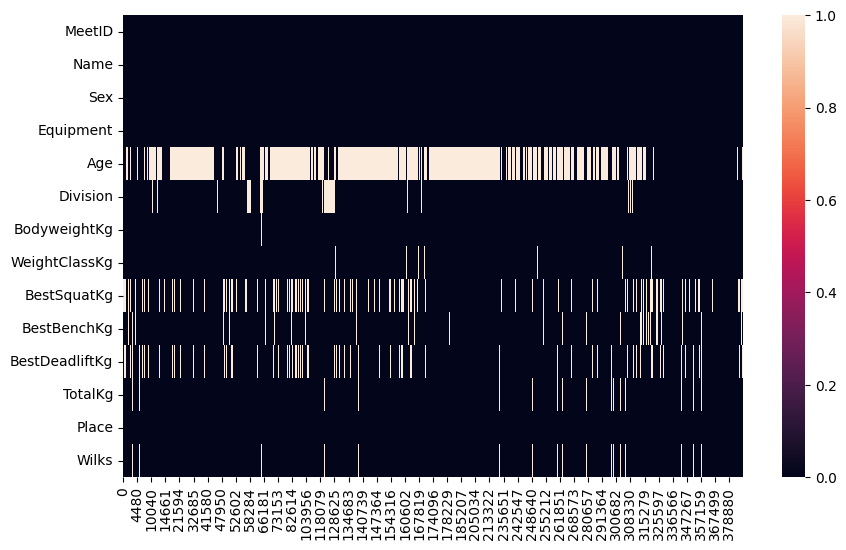

In [33]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.isna().transpose());

Заполнение пропусков

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 131989 entries, 0 to 386412
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   MeetID          131989 non-null  object 
 1   Name            131989 non-null  object 
 2   Sex             131989 non-null  object 
 3   Equipment       131989 non-null  object 
 4   Age             53077 non-null   float64
 5   Division        125978 non-null  object 
 6   BodyweightKg    131680 non-null  float64
 7   WeightClassKg   131112 non-null  object 
 8   BestSquatKg     108337 non-null  float64
 9   BestBenchKg     126701 non-null  float64
 10  BestDeadliftKg  115822 non-null  float64
 11  TotalKg         128396 non-null  float64
 12  Place           131485 non-null  object 
 13  Wilks           128087 non-null  float64
dtypes: float64(7), object(7)
memory usage: 19.1+ MB


In [35]:
df['BodyweightKg'].mean()

np.float64(85.3414074954435)

In [36]:
df['BodyweightKg'].median()

82.1

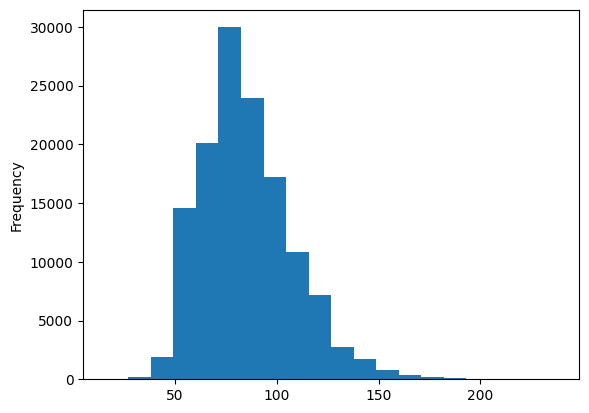

In [37]:
df['BodyweightKg'].plot(kind='hist', bins=20);

In [38]:
df['BodyweightKg'].fillna(df['BodyweightKg'].median())

,BodyweightKg
0,59.60
1,58.51
4,63.68
5,62.41
6,67.31
...,...
386398,86.73
386402,97.43
386403,98.79
386406,99.97


In [39]:
df['BodyweightKg'].isna().sum()

np.int64(309)

In [40]:
df['BodyweightKg'] = df['BodyweightKg'].fillna(df['BodyweightKg'].median())
# df['BodyweightKg'].fillna(df['BodyweightKg'].median(), inplace=True)

/tmp/ipython-input-1132702094.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['BodyweightKg'] = df['BodyweightKg'].fillna(df['BodyweightKg'].median())


In [41]:
df['BodyweightKg'].isna().sum()

np.int64(0)

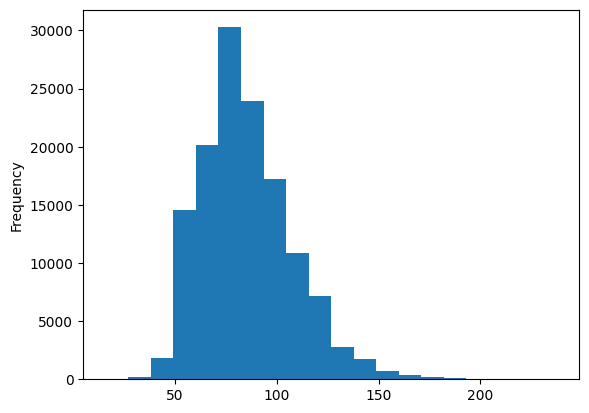

In [42]:
df['BodyweightKg'].plot(kind='hist', bins=20);

Признак качественный

In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 131989 entries, 0 to 386412
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   MeetID          131989 non-null  object 
 1   Name            131989 non-null  object 
 2   Sex             131989 non-null  object 
 3   Equipment       131989 non-null  object 
 4   Age             53077 non-null   float64
 5   Division        125978 non-null  object 
 6   BodyweightKg    131989 non-null  float64
 7   WeightClassKg   131112 non-null  object 
 8   BestSquatKg     108337 non-null  float64
 9   BestBenchKg     126701 non-null  float64
 10  BestDeadliftKg  115822 non-null  float64
 11  TotalKg         128396 non-null  float64
 12  Place           131485 non-null  object 
 13  Wilks           128087 non-null  float64
dtypes: float64(7), object(7)
memory usage: 19.1+ MB


In [44]:
df['Division'].value_counts()

,count
Division,
Open,21465
Boys,14753
R-O,10453
Amateur Open,5038
R-JR,3315
...,...
F-OFRC-U,1
F-T3FX-X,1
F-NFR-X,1


In [45]:
df['Division'] = df['Division'].str.lower()

df['Division'].value_counts()

/tmp/ipython-input-2670207331.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Division'] = df['Division'].str.lower()


,count
Division,
open,21679
boys,14753
r-o,10453
amateur open,5076
r-jr,3315
...,...
f-t3fx-x,1
f-nfr-x,1
f-ofr-u,1


In [46]:
df['Division'].mode()

,Division
0,open


In [47]:
division_mode = df['Division'].mode().iloc[0]
division_mode

'open'

In [48]:
df['Division'] = df['Division'].fillna(df['Division'].mode())
df['Division'].isna().sum()

/tmp/ipython-input-4131555147.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Division'] = df['Division'].fillna(df['Division'].mode())


np.int64(6011)

In [49]:
df['Division'] = df['Division'].fillna(df['Division'].mode()[0])
df['Division'].isna().sum()

/tmp/ipython-input-4262208559.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Division'] = df['Division'].fillna(df['Division'].mode()[0])


np.int64(0)

In [50]:
df['Division'] = df['Division'].fillna(division_mode)


/tmp/ipython-input-3195528898.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Division'] = df['Division'].fillna(division_mode)


np.int64(0)

In [51]:
df['Division'].isna().sum()

np.int64(0)

Indicator

In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 131989 entries, 0 to 386412
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   MeetID          131989 non-null  object 
 1   Name            131989 non-null  object 
 2   Sex             131989 non-null  object 
 3   Equipment       131989 non-null  object 
 4   Age             53077 non-null   float64
 5   Division        131989 non-null  object 
 6   BodyweightKg    131989 non-null  float64
 7   WeightClassKg   131112 non-null  object 
 8   BestSquatKg     108337 non-null  float64
 9   BestBenchKg     126701 non-null  float64
 10  BestDeadliftKg  115822 non-null  float64
 11  TotalKg         128396 non-null  float64
 12  Place           131485 non-null  object 
 13  Wilks           128087 non-null  float64
dtypes: float64(7), object(7)
memory usage: 19.1+ MB


In [53]:
df['Place'].value_counts()

,count
Place,
1,64521
2,21006
3,11305
4,7270
5,5083
...,...
73,1
74,1
75,1


In [54]:
df['Place_nan'] = 0
df.head()

/tmp/ipython-input-3307752679.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Place_nan'] = 0


,MeetID,Name,Sex,Equipment,Age,Division,BodyweightKg,WeightClassKg,BestSquatKg,BestBenchKg,BestDeadliftKg,TotalKg,Place,Wilks,Place_nan
0,0,Angie Belk Terry,F,Wraps,47.0,mst 45-49,59.60,60,47.63,20.41,70.31,138.35,1,155.05,0
1,0,Dawn Bogart,F,Single-ply,42.0,mst 40-44,58.51,60,142.88,95.25,163.29,401.42,1,456.38,0
4,0,Destiny Dula,F,Raw,18.0,teen 18-19,63.68,67.5,NaN,31.75,90.72,122.47,1,130.47,0
5,0,Courtney Norris,F,Wraps,28.0,open senior,62.41,67.5,170.10,77.11,145.15,392.36,1,424.40,0
6,0,Maureen Clary,F,Raw,60.0,mst 60-64,67.31,67.5,124.74,95.25,163.29,383.28,1,391.98,0


In [55]:
df.loc[df['Place'].isna(), 'Place_nan'] = 1
df[df['Place'].isna()].head()

,MeetID,Name,Sex,Equipment,Age,Division,BodyweightKg,WeightClassKg,BestSquatKg,BestBenchKg,BestDeadliftKg,TotalKg,Place,Wilks,Place_nan
3517,62,Pam McKeage,F,Raw,32.0,open,68.9,NaN,NaN,47.5,95.0,142.5,NaN,143.34,1
4927,81,Chandan McCall,M,Raw,17.0,teen,116.8,NaN,215.0,140.0,220.0,575.0,NaN,332.76,1
4928,81,Paolo DeMarco,M,Raw,19.0,teen,77.1,NaN,150.0,115.0,165.0,430.0,NaN,300.68,1
4929,81,Keller Nicolai,M,Raw,16.0,teen,102.5,NaN,157.5,105.0,187.5,450.0,NaN,271.26,1
4934,81,Lisa O'Kane,F,Raw,29.0,open,65.3,NaN,115.0,70.0,125.0,310.0,NaN,324.12,1


In [56]:
df['Place_nan'].value_counts()

,count
Place_nan,
0,131485
1,504


In [57]:
df['Place'].isna().sum()

np.int64(504)

In [58]:
df['Place'].fillna(0, inplace=True)
df['Place'].isna().sum()

/tmp/ipython-input-586890117.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Place'].fillna(0, inplace=True)
/tmp/ipython-input-586890117.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Place'].fillna(0, inplace=True)


np.int64(0)

In [59]:
df[df['Place_nan'] == 1].head()

,MeetID,Name,Sex,Equipment,Age,Division,BodyweightKg,WeightClassKg,BestSquatKg,BestBenchKg,BestDeadliftKg,TotalKg,Place,Wilks,Place_nan
3517,62,Pam McKeage,F,Raw,32.0,open,68.9,NaN,NaN,47.5,95.0,142.5,0,143.34,1
4927,81,Chandan McCall,M,Raw,17.0,teen,116.8,NaN,215.0,140.0,220.0,575.0,0,332.76,1
4928,81,Paolo DeMarco,M,Raw,19.0,teen,77.1,NaN,150.0,115.0,165.0,430.0,0,300.68,1
4929,81,Keller Nicolai,M,Raw,16.0,teen,102.5,NaN,157.5,105.0,187.5,450.0,0,271.26,1
4934,81,Lisa O'Kane,F,Raw,29.0,open,65.3,NaN,115.0,70.0,125.0,310.0,0,324.12,1


Неизвестность¶

In [60]:
df['WeightClassKg'].value_counts()

,count
WeightClassKg,
90,12781
82.5,12059
75,12035
100,11751
67.5,9630
110,8800
125,6732
93,5718
83,5477


In [61]:
df['WeightClassKg'].fillna('Unknown', inplace=True)

df.isna().sum()

/tmp/ipython-input-1199767507.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['WeightClassKg'].fillna('Unknown', inplace=True)
/tmp/ipython-input-1199767507.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['WeightClassKg'].fillna('Unknown', inplace=True)


,0
MeetID,0
Name,0
Sex,0
Equipment,0
Age,78912
Division,0
BodyweightKg,0
WeightClassKg,0
BestSquatKg,23652
BestBenchKg,5288


Более умное заполнение средними/медианами/модами

In [62]:
df['Age'].isna().sum()

np.int64(78912)

In [63]:
df['Division'].value_counts()

,count
Division,
open,27690
boys,14753
r-o,10453
amateur open,5076
r-jr,3315
...,...
f-t3fx-x,1
f-nfr-x,1
f-ofr-u,1


In [64]:
df.groupby('Division')['Age'].median()

,Age
Division,
-100kg,29.0
11-12r,12.0
12*13,12.5
12-13,13.0
13-15,14.0
...,...
yth,NaN
м1 40-49,NaN
м2 50-59,NaN


In [65]:
df[df['Division'] == 'м1 40-49']

,MeetID,Name,Sex,Equipment,Age,Division,BodyweightKg,WeightClassKg,BestSquatKg,BestBenchKg,BestDeadliftKg,TotalKg,Place,Wilks,Place_nan
383175,8452,Vladimir Gavrish,M,Wraps,NaN,м1 40-49,80.9,82.5,185.0,125.0,210.0,520.0,1,352.53,0
383191,8452,Vyacheslav Bondarev,M,Wraps,NaN,м1 40-49,88.8,90,195.0,165.0,225.0,585.0,1,376.05,0
383213,8452,Konstantin Udalov,M,Wraps,NaN,м1 40-49,93.0,100,230.0,160.0,240.0,630.0,1,395.76,0
383214,8452,Oleg Usatenko,M,Wraps,NaN,м1 40-49,99.5,100,220.0,150.0,220.0,590.0,2,359.79,0
383235,8452,Anatoliy Andreev,M,Wraps,NaN,м1 40-49,122.3,125,190.0,140.0,200.0,530.0,2,303.41,0
383279,8452,Nurzhan Zhalpakov,M,Raw,NaN,м1 40-49,66.3,67.5,NaN,115.0,NaN,115.0,1,89.96,0
383297,8452,Anatoliy Dorokhov,M,Raw,NaN,м1 40-49,73.5,75,NaN,150.0,NaN,150.0,1,108.42,0
383325,8452,Vitaliy Kravtsov,M,Raw,NaN,м1 40-49,81.0,82.5,NaN,155.0,NaN,155.0,2,105.00,0
383326,8452,Vladimir Ashchepkov,M,Raw,NaN,м1 40-49,80.0,82.5,NaN,140.0,NaN,140.0,3,95.58,0
383369,8452,Igor Maksimov,M,Raw,NaN,м1 40-49,99.4,100,NaN,135.0,NaN,135.0,1,82.36,0


In [66]:
age_by_division = df.groupby('Division')['Age'].transform('median')
age_by_division

,Age
0,47.0
1,42.0
4,19.0
5,28.0
6,60.5
...,...
386398,NaN
386402,NaN
386403,NaN
386406,NaN


In [67]:
df[df['Age'].isna()]

,MeetID,Name,Sex,Equipment,Age,Division,BodyweightKg,WeightClassKg,BestSquatKg,BestBenchKg,BestDeadliftKg,TotalKg,Place,Wilks,Place_nan
834,15,Gloria Moses,F,Raw,NaN,open,73.00,75,145.0,80.0,165.0,390.0,1,377.21,0
861,15,Martin Drake,M,Raw,NaN,lm 65-69,74.93,75,NaN,130.0,NaN,130.0,1,92.69,0
1096,19,Lucas Johnson,M,Raw,NaN,r open,100.00,100,227.5,145.0,320.0,692.5,1,421.45,0
1117,21,W. Jackson,M,Single-ply,NaN,open,52.00,52,142.5,80.0,195.0,417.5,1,409.68,0
1118,21,T. Carver,M,Single-ply,NaN,open,52.00,52,137.5,77.5,185.0,400.0,2,392.51,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
386398,8481,Molly Headly,F,Multi-ply,NaN,elite,86.73,90,NaN,NaN,220.0,220.0,1,193.20,0
386402,8481,Bryan Doderdruk,M,Multi-ply,NaN,elite,97.43,100,NaN,NaN,352.5,352.5,2,216.85,0
386403,8481,Shawn Schumaker,M,Multi-ply,NaN,elite,98.79,100,NaN,NaN,365.0,365.0,1,223.24,0
386406,8481,Matthew Ladewski,M,Multi-ply,NaN,elite,99.97,100,NaN,NaN,325.0,325.0,4,197.82,0


In [68]:
idx = 861

In [69]:
age_by_division.loc[idx]

np.float64(67.0)

In [70]:
df['Age'] = df['Age'].fillna(age_by_division)
df.head()

/tmp/ipython-input-577613703.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Age'] = df['Age'].fillna(age_by_division)


,MeetID,Name,Sex,Equipment,Age,Division,BodyweightKg,WeightClassKg,BestSquatKg,BestBenchKg,BestDeadliftKg,TotalKg,Place,Wilks,Place_nan
0,0,Angie Belk Terry,F,Wraps,47.0,mst 45-49,59.60,60,47.63,20.41,70.31,138.35,1,155.05,0
1,0,Dawn Bogart,F,Single-ply,42.0,mst 40-44,58.51,60,142.88,95.25,163.29,401.42,1,456.38,0
4,0,Destiny Dula,F,Raw,18.0,teen 18-19,63.68,67.5,NaN,31.75,90.72,122.47,1,130.47,0
5,0,Courtney Norris,F,Wraps,28.0,open senior,62.41,67.5,170.10,77.11,145.15,392.36,1,424.40,0
6,0,Maureen Clary,F,Raw,60.0,mst 60-64,67.31,67.5,124.74,95.25,163.29,383.28,1,391.98,0


In [71]:
df.loc[[idx]]

,MeetID,Name,Sex,Equipment,Age,Division,BodyweightKg,WeightClassKg,BestSquatKg,BestBenchKg,BestDeadliftKg,TotalKg,Place,Wilks,Place_nan
861,15,Martin Drake,M,Raw,67.0,lm 65-69,74.93,75,NaN,130.0,NaN,130.0,1,92.69,0


In [72]:
df['Age'].isna().sum()

np.int64(24228)

In [73]:
division_missing_age = df[df['Age'].isna()]['Division'].value_counts()
division_missing_age

,count
Division,
boys,14753
teen 14-18,1113
sub-junior,1009
varsity,604
nov,589
...,...
dt - m2 45-49,1
m40/44,1
dt - m40/44,1


In [74]:
division_missing_age_df = division_missing_age.index.str.extract('(\d\d)-(\d\d)|(\d\d)')
division_missing_age_df


<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipython-input-707808835.py:1: SyntaxWarning: invalid escape sequence '\d'
  division_missing_age_df = division_missing_age.index.str.extract('(\d\d)-(\d\d)|(\d\d)')


,0,1,2
0,NaN,NaN,NaN
1,14,18,NaN
2,NaN,NaN,NaN
3,NaN,NaN,NaN
4,NaN,NaN,NaN
...,...,...,...
897,45,49,NaN
898,NaN,NaN,40
899,NaN,NaN,40
900,70,79,NaN


In [75]:
division_missing_age_df['Division'] = division_missing_age.index
division_missing_age_df

,0,1,2,Division
0,NaN,NaN,NaN,boys
1,14,18,NaN,teen 14-18
2,NaN,NaN,NaN,sub-junior
3,NaN,NaN,NaN,varsity
4,NaN,NaN,NaN,nov
...,...,...,...,...
897,45,49,NaN,dt - m2 45-49
898,NaN,NaN,40,m40/44
899,NaN,NaN,40,dt - m40/44
900,70,79,NaN,м4 70-79


In [77]:
import numpy as np

In [78]:
def count_mean(x):
    if not x[0] is np.nan:
        return (int(x[0]) + int(x[1])) / 2
    elif not x[2] is np.nan:
        return x[2]
    else:
        return np.nan

division_missing_age_df['mean'] = division_missing_age_df.apply(count_mean, axis=1)
division_missing_age_df

,0,1,2,Division,mean
0,NaN,NaN,NaN,boys,NaN
1,14,18,NaN,teen 14-18,16.0
2,NaN,NaN,NaN,sub-junior,NaN
3,NaN,NaN,NaN,varsity,NaN
4,NaN,NaN,NaN,nov,NaN
...,...,...,...,...,...
897,45,49,NaN,dt - m2 45-49,47.0
898,NaN,NaN,40,m40/44,40
899,NaN,NaN,40,dt - m40/44,40
900,70,79,NaN,м4 70-79,74.5


In [79]:
division_missing_age_df['mean'].isna().sum()

np.int64(496)

In [80]:
df = df.merge(division_missing_age_df[['Division', 'mean']], on='Division', how='left')
df.head()

,MeetID,Name,Sex,Equipment,Age,Division,BodyweightKg,WeightClassKg,BestSquatKg,BestBenchKg,BestDeadliftKg,TotalKg,Place,Wilks,Place_nan,mean
0,0,Angie Belk Terry,F,Wraps,47.0,mst 45-49,59.60,60,47.63,20.41,70.31,138.35,1,155.05,0,NaN
1,0,Dawn Bogart,F,Single-ply,42.0,mst 40-44,58.51,60,142.88,95.25,163.29,401.42,1,456.38,0,NaN
2,0,Destiny Dula,F,Raw,18.0,teen 18-19,63.68,67.5,NaN,31.75,90.72,122.47,1,130.47,0,NaN
3,0,Courtney Norris,F,Wraps,28.0,open senior,62.41,67.5,170.10,77.11,145.15,392.36,1,424.40,0,NaN
4,0,Maureen Clary,F,Raw,60.0,mst 60-64,67.31,67.5,124.74,95.25,163.29,383.28,1,391.98,0,NaN


In [81]:
df['Age'] = df['Age'].fillna(df['Age'].median())
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131989 entries, 0 to 131988
Data columns (total 16 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   MeetID          131989 non-null  object 
 1   Name            131989 non-null  object 
 2   Sex             131989 non-null  object 
 3   Equipment       131989 non-null  object 
 4   Age             131989 non-null  float64
 5   Division        131989 non-null  object 
 6   BodyweightKg    131989 non-null  float64
 7   WeightClassKg   131989 non-null  object 
 8   BestSquatKg     108337 non-null  float64
 9   BestBenchKg     126701 non-null  float64
 10  BestDeadliftKg  115822 non-null  float64
 11  TotalKg         128396 non-null  float64
 12  Place           131989 non-null  object 
 13  Wilks           128087 non-null  float64
 14  Place_nan       131989 non-null  int64  
 15  mean            2708 non-null    object 
dtypes: float64(7), int64(1), object(8)
memory usage: 16.1+ M

In [82]:
df.drop(columns='mean', inplace=True)

Интерполировать

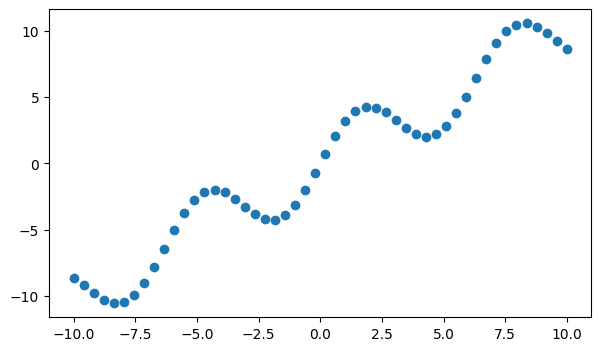

In [83]:
x = np.linspace(-10, 10, num=50)
y = 2.5 * np.sin(x) + x

plt.figure(figsize=(7, 4))
plt.scatter(x, y);

In [84]:
df = pd.DataFrame({'x': x, 'true_y': y})
df

,x,true_y
0,-10.000000,-8.639947
1,-9.591837,-9.176130
2,-9.183673,-9.780612
3,-8.775510,-10.287018
4,-8.367347,-10.545089
5,-7.959184,-10.445362
6,-7.551020,-9.937163
7,-7.142857,-9.036928
8,-6.734694,-7.825502
9,-6.326531,-6.434860


In [85]:
np.random.seed(9)

df['y'] = df['true_y']
df.loc[np.random.randint(0, 50, 10), 'y'] = np.nan
df.head()

,x,true_y,y
0,-10.000000,-8.639947,-8.639947
1,-9.591837,-9.176130,NaN
2,-9.183673,-9.780612,-9.780612
3,-8.775510,-10.287018,-10.287018
4,-8.367347,-10.545089,-10.545089


In [86]:
nan_x = df[df['y'].isna()]['x']
nan_y = df[df['y'].isna()]['true_y']

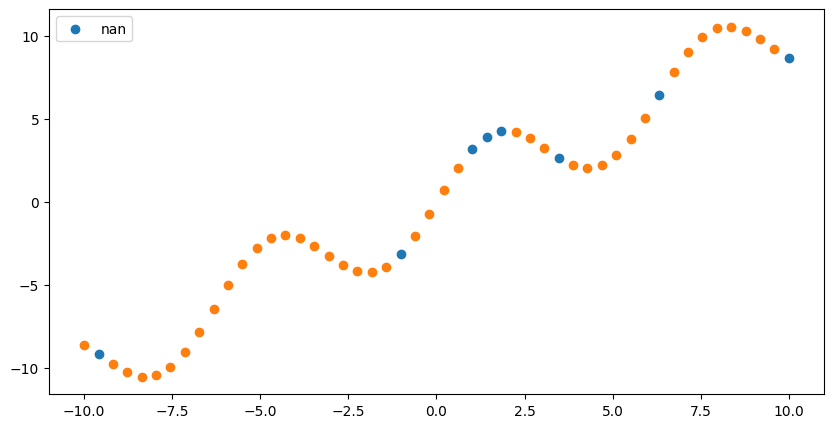

In [87]:
plt.figure(figsize=(10, 5))
plt.scatter(nan_x, nan_y, label='nan')
plt.scatter(df['x'], df['y'])
plt.legend();

linear interpolation

In [88]:
df['y_lin'] = df['y'].interpolate()
df.head()

,x,true_y,y,y_lin
0,-10.000000,-8.639947,-8.639947,-8.639947
1,-9.591837,-9.176130,NaN,-9.210279
2,-9.183673,-9.780612,-9.780612,-9.780612
3,-8.775510,-10.287018,-10.287018,-10.287018
4,-8.367347,-10.545089,-10.545089,-10.545089


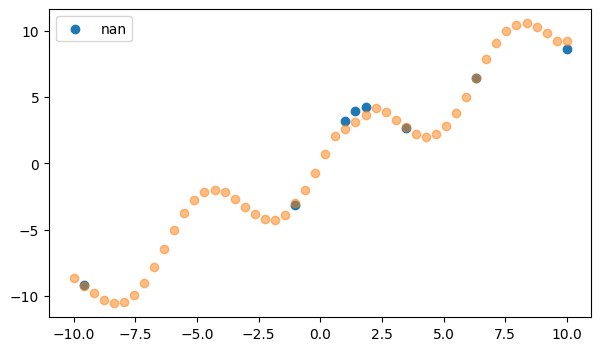

In [89]:
plt.figure(figsize=(7, 4))
plt.scatter(nan_x, nan_y, label='nan')
plt.scatter(df['x'], df['y_lin'], alpha=0.5)
plt.legend();

In [90]:
np.mean(np.abs(df['true_y'] - df['y_lin']))

np.float64(0.05506338361659317)

padding

In [91]:
df['y_pad'] = df['y'].interpolate(method='pad', limit=2)
df.head()

/tmp/ipython-input-3845021345.py:1: FutureWarning: Series.interpolate with method=pad is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df['y_pad'] = df['y'].interpolate(method='pad', limit=2)


,x,true_y,y,y_lin,y_pad
0,-10.000000,-8.639947,-8.639947,-8.639947,-8.639947
1,-9.591837,-9.176130,NaN,-9.210279,-8.639947
2,-9.183673,-9.780612,-9.780612,-9.780612,-9.780612
3,-8.775510,-10.287018,-10.287018,-10.287018,-10.287018
4,-8.367347,-10.545089,-10.545089,-10.545089,-10.545089


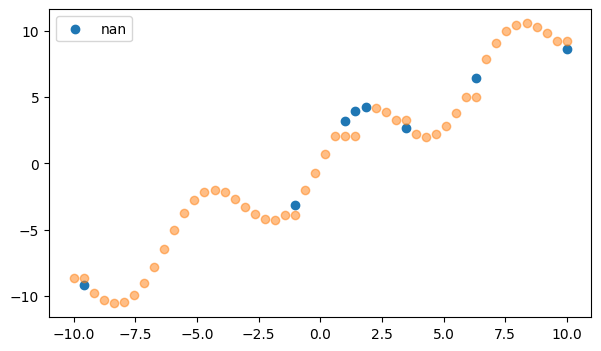

In [92]:
plt.figure(figsize=(7, 4))
plt.scatter(nan_x, nan_y, label='nan')
plt.scatter(df['x'], df['y_pad'], alpha=0.5)
plt.legend();

In [93]:
np.mean(np.abs(df['true_y'] - df['y_pad']))

np.float64(0.1385076673888301)

In [94]:
df['y_pad_fillna'] = df['y']
df['y_pad_fillna'] = df['y_pad_fillna'].fillna(method="pad")
df.head()

/tmp/ipython-input-617870886.py:2: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df['y_pad_fillna'] = df['y_pad_fillna'].fillna(method="pad")


,x,true_y,y,y_lin,y_pad,y_pad_fillna
0,-10.000000,-8.639947,-8.639947,-8.639947,-8.639947,-8.639947
1,-9.591837,-9.176130,NaN,-9.210279,-8.639947,-8.639947
2,-9.183673,-9.780612,-9.780612,-9.780612,-9.780612,-9.780612
3,-8.775510,-10.287018,-10.287018,-10.287018,-10.287018,-10.287018
4,-8.367347,-10.545089,-10.545089,-10.545089,-10.545089,-10.545089


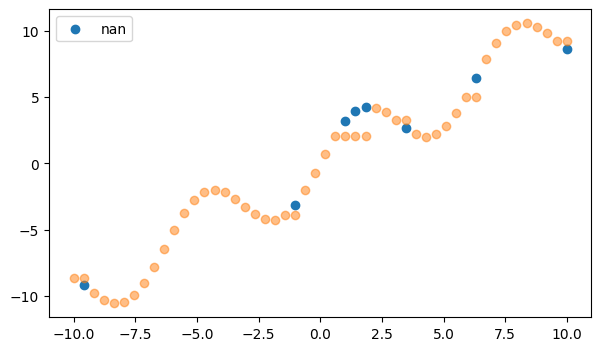

In [95]:
plt.figure(figsize=(7, 4))
plt.scatter(nan_x, nan_y, label='nan')
plt.scatter(df['x'], df['y_pad_fillna'], alpha=0.5)
plt.legend();

In [96]:
np.mean(np.abs(df['true_y'] - df['y_pad_fillna']))

np.float64(0.1797343233478001)

In [97]:
df['y_bfill'] = df['y']

df.head()

,x,true_y,y,y_lin,y_pad,y_pad_fillna,y_bfill
0,-10.000000,-8.639947,-8.639947,-8.639947,-8.639947,-8.639947,-8.639947
1,-9.591837,-9.176130,NaN,-9.210279,-8.639947,-8.639947,NaN
2,-9.183673,-9.780612,-9.780612,-9.780612,-9.780612,-9.780612,-9.780612
3,-8.775510,-10.287018,-10.287018,-10.287018,-10.287018,-10.287018,-10.287018
4,-8.367347,-10.545089,-10.545089,-10.545089,-10.545089,-10.545089,-10.545089


/tmp/ipython-input-2330526510.py:1: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df['y_bfill'] = df['y_bfill'].fillna(method="bfill")


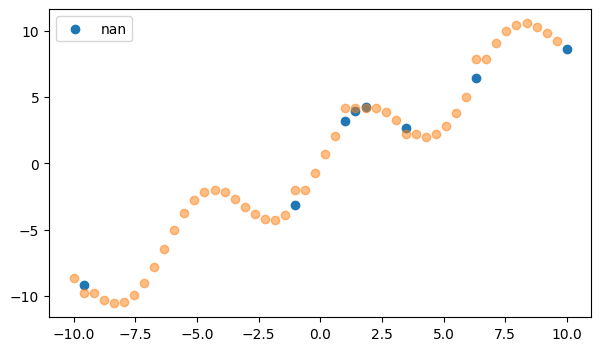

In [98]:
df['y_bfill'] = df['y_bfill'].fillna(method="bfill")
plt.figure(figsize=(7, 4))
plt.scatter(nan_x, nan_y, label='nan')
plt.scatter(df['x'], df['y_bfill'], alpha=0.5)
plt.legend();

In [99]:
np.mean(np.abs(df['true_y'] - df['y_bfill']))

np.float64(0.10112029186156916)

nearest

In [100]:
df['y_nearest'] = df['y'].interpolate(method='nearest')
df.head()

,x,true_y,y,y_lin,y_pad,y_pad_fillna,y_bfill,y_nearest
0,-10.000000,-8.639947,-8.639947,-8.639947,-8.639947,-8.639947,-8.639947,-8.639947
1,-9.591837,-9.176130,NaN,-9.210279,-8.639947,-8.639947,-9.780612,-8.639947
2,-9.183673,-9.780612,-9.780612,-9.780612,-9.780612,-9.780612,-9.780612,-9.780612
3,-8.775510,-10.287018,-10.287018,-10.287018,-10.287018,-10.287018,-10.287018,-10.287018
4,-8.367347,-10.545089,-10.545089,-10.545089,-10.545089,-10.545089,-10.545089,-10.545089


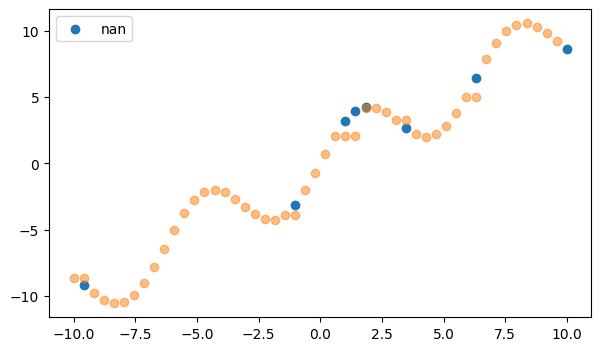

In [101]:
plt.figure(figsize=(7, 4))
plt.scatter(nan_x, nan_y, label='nan')
plt.scatter(df['x'], df['y_nearest'], alpha=0.5)
plt.legend();

In [102]:
np.mean(np.abs(df['true_y'] - df['y_nearest']))

np.float64(0.12860154332846715)

polynomial

In [103]:
df['y_poly'] = df['y'].interpolate(method='polynomial', order=2)
df.head()

,x,true_y,y,y_lin,y_pad,y_pad_fillna,y_bfill,y_nearest,y_poly
0,-10.000000,-8.639947,-8.639947,-8.639947,-8.639947,-8.639947,-8.639947,-8.639947,-8.639947
1,-9.591837,-9.176130,NaN,-9.210279,-8.639947,-8.639947,-9.780612,-8.639947,-9.221393
2,-9.183673,-9.780612,-9.780612,-9.780612,-9.780612,-9.780612,-9.780612,-9.780612,-9.780612
3,-8.775510,-10.287018,-10.287018,-10.287018,-10.287018,-10.287018,-10.287018,-10.287018,-10.287018
4,-8.367347,-10.545089,-10.545089,-10.545089,-10.545089,-10.545089,-10.545089,-10.545089,-10.545089


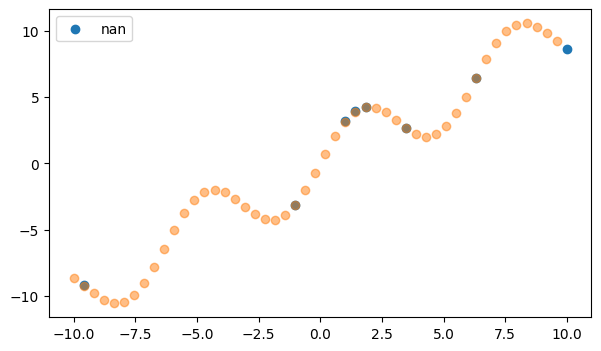

In [104]:
df['y_poly'] = df['y'].interpolate(method='polynomial', order=2)
plt.figure(figsize=(7, 4))
plt.scatter(nan_x, nan_y, label='nan')
plt.scatter(df['x'], df['y_poly'], alpha=0.5)
plt.legend();

In [105]:
np.mean(np.abs(df['true_y'] - df['y_poly']))

np.float64(0.004505216798914928)